In [107]:
import numpy as np
from scipy import interpolate
import matplotlib.pyplot as plt

In [108]:
# Physiologically acceptable range of HR and distances between R.
# Signals outside of it are treated like acquisition error and filtered out.
PHYSIO_HR = np.array([30, 200])
PHYSIO_RR = (60 / PHYSIO_HR)[::-1]
PHYSIO_RR

array([0.3, 2. ])

RR_raw_chf.shape=(135470,)


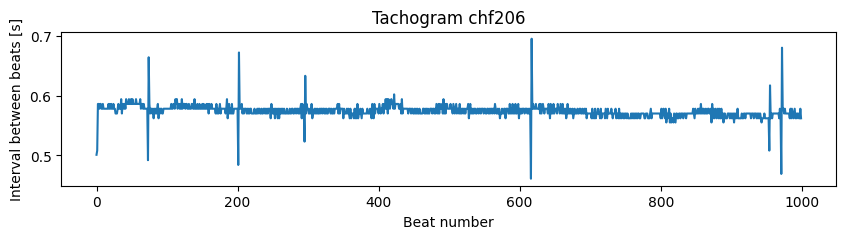

In [109]:
# Raw = not-filtered
RR_raw_chf = np.loadtxt("data/chf206.dat")

print(f"{RR_raw_chf.shape=}")

plt.figure(figsize=(10, 2))
fragment_len = 1000
plt.plot(np.arange(fragment_len), RR_raw_chf[:fragment_len])
plt.xlabel("Beat number")
plt.ylabel("Interval between beats [s]")
plt.title("Tachogram chf206")
plt.show()

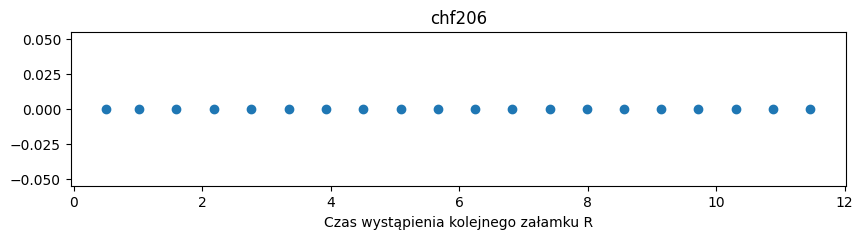

In [110]:
# Calculate cumsum BEFORE filtering, to keep correct timings
RR_chf_t_raw = np.cumsum(RR_raw_chf)

fragment_len = 20
plt.figure(figsize=(10, 2))
plt.scatter(RR_chf_t_raw[:fragment_len], np.zeros(fragment_len))
plt.xlabel("Czas wystąpienia kolejnego załamku R")
plt.title("chf206")
plt.show()

In [111]:
RR_raw_chf.min(), RR_raw_chf.max()

(np.float64(0.25), np.float64(20.242))

In [113]:
# Filter out non-physiological
chf_physio_idx = (RR_raw_chf >= PHYSIO_RR[0]) & (RR_raw_chf <= PHYSIO_RR[1])
RR_chf = RR_raw_chf[chf_physio_idx]
RR_chf_t = RR_chf_t_raw[chf_physio_idx]

print(f"Filtered: {RR_raw_chf.shape[0]-RR_chf.shape[0]}")

RR_chf.shape

Filtered: 28


(135442,)

In [ ]:
RR_raw_nsr = np.loadtxt("data/nsr001.dat")

print(f"{RR_raw_nsr.shape=}")

fragment_len = 1000
plt.figure(figsize=(10, 2))
plt.plot(np.arange(fragment_len), RR_raw_nsr[:fragment_len])
plt.xlabel("Beat number")
plt.ylabel("Interval between beats [s]")
plt.title("Tachogram nsr001")
plt.show()

In [ ]:
RR_raw_nsr.min(), RR_raw_nsr.max()

In [ ]:
RR_nsr_t_raw = np.cumsum(RR_raw_nsr)

fragment_len = 20
plt.figure(figsize=(10, 2))
plt.scatter(RR_nsr_t_raw[:fragment_len], np.zeros(fragment_len))
plt.xlabel("Czas wystąpienia kolejnego załamku R")
plt.title("nsr001")
plt.show()

In [114]:
# Filter out non-physiological
nsr_physio_idx = (RR_raw_nsr >= PHYSIO_RR[0]) & (RR_raw_nsr <= PHYSIO_RR[1])
RR_nsr = RR_raw_nsr[nsr_physio_idx]
RR_nsr_t = RR_nsr_t_raw[nsr_physio_idx]

print(f"Filtered: {RR_raw_nsr.shape[0]-RR_nsr.shape[0]}")

RR_nsr.shape

Filtered: 3


(106457,)